# 01 · Exploratory Data Analysis — Money-mule detection

**Problem.** Bank A opens savings accounts fully online. Some customers ("mules") open accounts only to receive money
swindled from others. We have **100,000 labelled development accounts** (`Target = 1` → mule) and **50,000 unlabelled
validation accounts**; we must output **P(mule)** for every validation account.

**How we are scored.** *"how close the predicted probabilities are to the actual outcome"*. That is a **probability
accuracy** metric (log-loss / Brier score), not only ranking (AUC). This matters later: a weighted loss
(which we use for the imbalance) inflates probabilities, so the final model **must be re-calibrated**.

Features are anonymised: `demog_*` = demographics, `txn_*` = transaction history, `others_*` = product holding,
logins etc., plus a few named ones (`account_opening_date`, `income`, `city_tier`, `occupation`, `os`, `email_domain`, `country_code`).

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import roc_auc_score
from src.data import DataLoader, ID, TARGET

BLUE, ORANGE, AQUA, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984'
DIVERGING = LinearSegmentedColormap.from_list('div', [BLUE, '#e9e8e4', ORANGE])
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'axes.titleweight': 'bold', 'axes.titlesize': 11})
pd.set_option('display.max_columns', 60, 'display.width', 200)

train, valid = DataLoader().load('train'), DataLoader().load('validation')
y = train[TARGET]
FEATURES = train.columns.drop([ID, TARGET])
print('train', train.shape, '| validation', valid.shape, '| memory %.0f MB' % (train.memory_usage(deep=True).sum() / 1e6))

train (100000, 178) | validation (50000, 177) | memory 147 MB


## 1. Feature inventory

In [2]:
group = pd.Series({c: c.split('_')[0] if c.split('_')[0] in ('demog', 'txn', 'others') else 'named' for c in FEATURES})
print(pd.crosstab(group, train[FEATURES].dtypes.astype(str)))
train.head()

col_0   datetime64[us]  float64  int64  str
row_0                                      
demog                0       34      3    6
named                1        0      0    6
others               0       32     13    0
txn                  0       81      0    0


,Primary key,Target,account_opening_date,country_code,demog_1,demog_2,income,demog_3,city_tier,occupation,demog_4,demog_5,demog_6,demog_7,demog_8,demog_9,demog_10,demog_11,demog_12,demog_13,demog_14,demog_15,demog_16,demog_17,demog_18,demog_19,demog_20,demog_21,demog_22,os,...,demog_30,demog_31,demog_32,demog_33,demog_34,demog_35,demog_36,demog_37,demog_38,others_33,others_34,others_35,others_36,others_37,others_38,others_39,others_40,others_41,txn_80,txn_81,demog_39,email_domain,demog_40,demog_41,others_42,others_43,others_44,others_45,demog_42,demog_43
0,1,0,2023-02-18,IN,53.0,3,100001 to 5L,101.0,Rural,Self_Employed,N,3.0,1.0,1.0,41.0,0.0,N,0.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,Y,ios,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0.0,0.0,1.0,1.0,1,gmail,low,1,NaN,0.0,NaN,NaN,1,medium
1,2,0,2023-02-01,IN,55.0,1,0 to 1L,101.0,Tier 1,Salaried,N,2.0,1.0,1.0,41.0,1.0,N,0.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,Y,and,...,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0,0,0,1,0,0,1,0.0,0.0,12.0,28.0,1,gmail,High,1,NaN,NaN,NaN,NaN,1,High
2,3,0,2022-12-09,IN,55.0,3,0 to 1L,101.0,Tier 2,Self_Employed,N,4.0,1.0,1.0,41.0,0.0,N,0.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,Y,and,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0,0,1,1,0,0,0,0.0,0.0,5.0,48.0,1,gmail,medium,1,NaN,NaN,NaN,NaN,1,High
3,4,0,2023-03-31,IN,53.0,3,100001 to 5L,101.0,Tier 7,Self_Employed,N,4.0,1.0,1.0,41.0,NaN,N,0.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,Y,and,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0.0,0.0,1.0,10.0,1,gmail,High,1,NaN,NaN,NaN,NaN,1,High
4,5,0,2023-01-17,IN,55.0,6,0 to 1L,101.0,Tier 1,Student,N,4.0,1.0,1.0,41.0,0.0,N,0.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,Y,and,...,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0.0,0.0,NaN,NaN,1,gmail,low,1,NaN,NaN,NaN,NaN,1,medium


## 2. Target — how imbalanced?

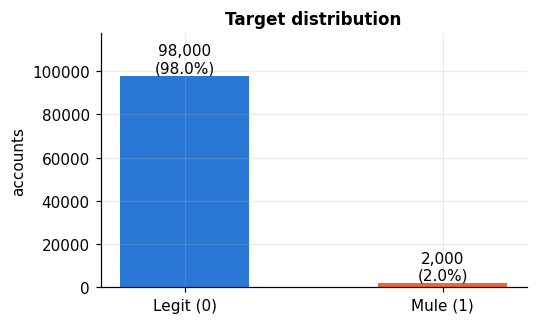

mule rate = 2.00%  ->  imbalance 1:49  (natural scale_pos_weight ≈ 49)
"no-skill" reference (predict 0.02 for everyone): log-loss = 0.0980, Brier = 0.0196


In [3]:
counts = y.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(['Legit (0)', 'Mule (1)'], counts.values, color=[BLUE, ORANGE], width=.5)
for i, v in enumerate(counts.values):
    ax.text(i, v, f'{v:,}\n({v / len(y):.1%})', ha='center', va='bottom')
ax.set(title='Target distribution', ylabel='accounts', ylim=(0, counts.max() * 1.2))
plt.show()

p = y.mean()
print(f'mule rate = {p:.2%}  ->  imbalance 1:{(1 - p) / p:.0f}  (natural scale_pos_weight ≈ {(1 - p) / p:.0f})')
print(f'"no-skill" reference (predict {p} for everyone): log-loss = {-(p * np.log(p) + (1 - p) * np.log(1 - p)):.4f}, Brier = {p * (1 - p):.4f}')

## 3. Missing values
Many columns go missing **together**. Grouping columns by identical missing-pattern shows the structure, and
comparing the mule rate when a block is missing vs present tells us whether missingness itself is informative.

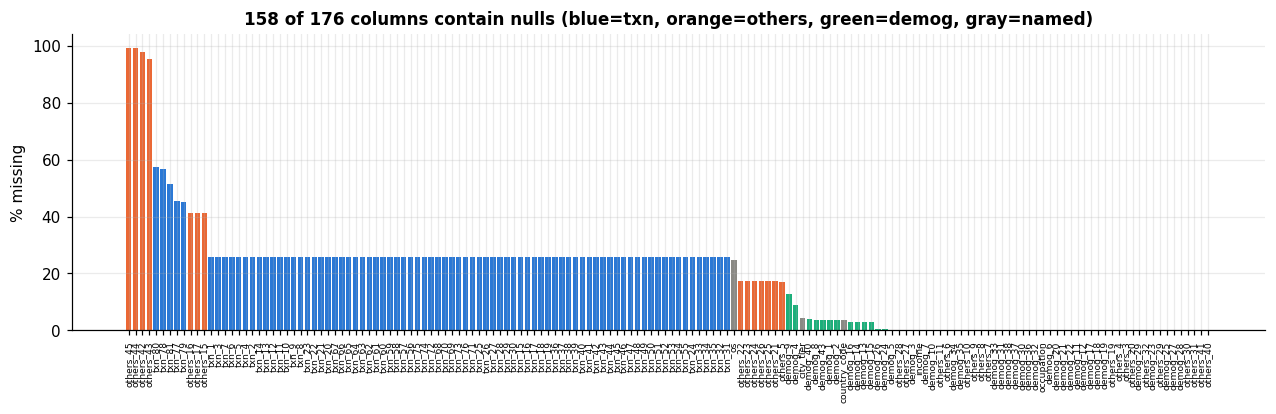

In [4]:
na = train[FEATURES].isna()
na_pct = na.mean().loc[lambda s: s > 0].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(14, 3.5))
ax.bar(range(len(na_pct)), na_pct.values * 100, color=[{'txn': BLUE, 'others': ORANGE, 'demog': AQUA}.get(group[c], GRAY) for c in na_pct.index], width=.8)
ax.set_xticks(range(len(na_pct)), na_pct.index, rotation=90, fontsize=6)
ax.set(title=f'{len(na_pct)} of {len(FEATURES)} columns contain nulls (blue=txn, orange=others, green=demog, gray=named)', ylabel='% missing')
plt.show()

In [5]:
mask_key = {c: na[c].values.tobytes() for c in na_pct.index}
rows = []
for cols in pd.Series(list(mask_key)).groupby([mask_key[c] for c in mask_key]).agg(list):
    m = na[cols[0]]
    rows.append({'columns': f'{cols[0]} … {cols[-1]}' if len(cols) > 1 else cols[0], 'n_cols': len(cols),
                 'missing_%': 100 * m.mean(), 'mule_rate_missing_%': 100 * y[m].mean(), 'mule_rate_present_%': 100 * y[~m].mean()})
blocks = pd.DataFrame(rows).sort_values('missing_%', ascending=False).round(2)
blocks

,columns,n_cols,missing_%,mule_rate_missing_%,mule_rate_present_%
32,others_45,1,99.31,2.01,0.00
31,others_44,1,99.13,2.02,0.11
33,others_42,1,97.90,2.04,0.14
30,others_43,1,95.42,2.09,0.13
25,txn_80,1,57.48,0.26,4.36
24,txn_78,1,56.73,0.37,4.14
27,txn_81,1,51.46,0.75,3.33
26,txn_77,1,45.42,0.42,3.31
23,txn_79,1,44.96,0.30,3.39
29,others_16 … others_15,3,41.36,0.66,2.94


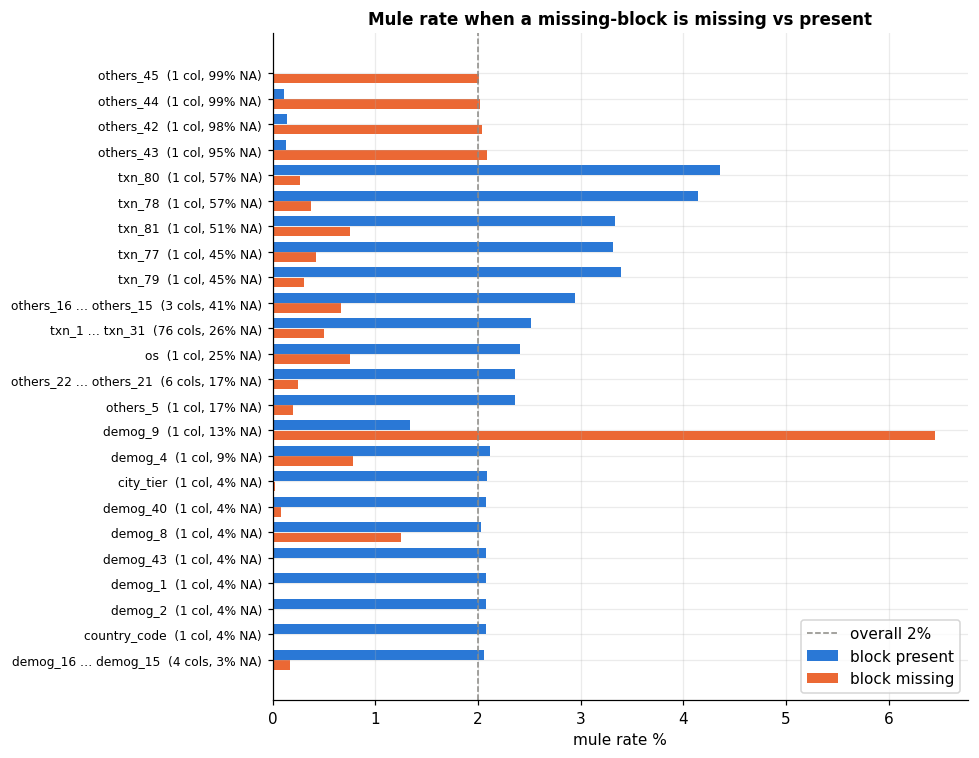

In [6]:
big = blocks[blocks['missing_%'] > 1].set_index('columns').iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 7))
yy = np.arange(len(big))
ax.barh(yy + .2, big['mule_rate_present_%'], .38, color=BLUE, label='block present')
ax.barh(yy - .2, big['mule_rate_missing_%'], .38, color=ORANGE, label='block missing')
ax.axvline(100 * p, color=GRAY, ls='--', lw=1, label='overall 2%')
ax.set_yticks(yy, [f"{c}  ({n} col{'s' * (n > 1)}, {m:.0f}% NA)" for c, n, m in zip(big.index, big.n_cols, big['missing_%'])], fontsize=8)
ax.set(xlabel='mule rate %', title='Mule rate when a missing-block is missing vs present')
ax.legend(loc='lower right'); plt.tight_layout(); plt.show()

## 4. Data-quality checks: constants, duplicates, sentinels, mixed types

In [7]:
nuniq = train[FEATURES].nunique()
print('constant columns (<=1 unique non-null value):', list(nuniq[nuniq <= 1].index))
dup = train.duplicated(subset=list(FEATURES), keep=False)
print(f'rows that are exact duplicates of another row (ignoring key): {dup.sum():,} '
      f'| mule rate among them {y[dup].mean():.2%} | txn block missing among them {train.loc[dup, "txn_1"].isna().mean():.0%}')
mule_keys = train.loc[y == 1, ID]
print(f'row order: the development file is SORTED by target - all {len(mule_keys):,} mules are the last rows '
      f'(Primary key {mule_keys.min():,}…{mule_keys.max():,}); validation keys run {valid[ID].min():,}…{valid[ID].max():,}')
for c in ['others_27', 'others_28']:
    print(f'{c}: value 9999 in {(train[c] == 9999).mean():.1%} of rows (sentinel, not a real number); other values range '
          f'{train.loc[train[c] != 9999, c].min():.0f}…{train.loc[train[c] != 9999, c].max():.0f}')
for c in ['demog_2', 'demog_4', 'income']:
    print(f'{c}: levels {sorted(train[c].dropna().unique(), key=str)}')

constant columns (<=1 unique non-null value): ['demog_7', 'demog_10', 'demog_12', 'txn_35', 'txn_36', 'txn_49', 'txn_50', 'txn_65', 'txn_70', 'txn_71', 'txn_72', 'demog_38']


rows that are exact duplicates of another row (ignoring key): 3,722 | mule rate among them 0.00% | txn block missing among them 98%
row order: the development file is SORTED by target - all 2,000 mules are the last rows (Primary key 98,001…100,000); validation keys run 9,000,001…9,050,000
others_27: value 9999 in 99.4% of rows (sentinel, not a real number); other values range -1…2037
others_28: value 9999 in 98.3% of rows (sentinel, not a real number); other values range -2…1702
demog_2: levels ['1', '10', '11', '15', '16', '17', '2', '3', '4', '5', '6', '7', '9', 'ZZ']
demog_4: levels ['1', '2', '3', '5', '6', '7', 'N']
income: levels ['0', '0 to 1L', '100001 to 5L', '10Crore to 15Crore', '10L to 25L', '15Crore to 20Crore', '20Crore to 35Crore', '25L to 50L', '3Crore to 5Crore', '50L to 3Crore', '5Crore to 10Crore', '5L to 10L']


## 5. Categorical features — mule rate by level
Dashed line = overall 2% mule rate. Labels show the number of accounts in each level (small levels are noisy).

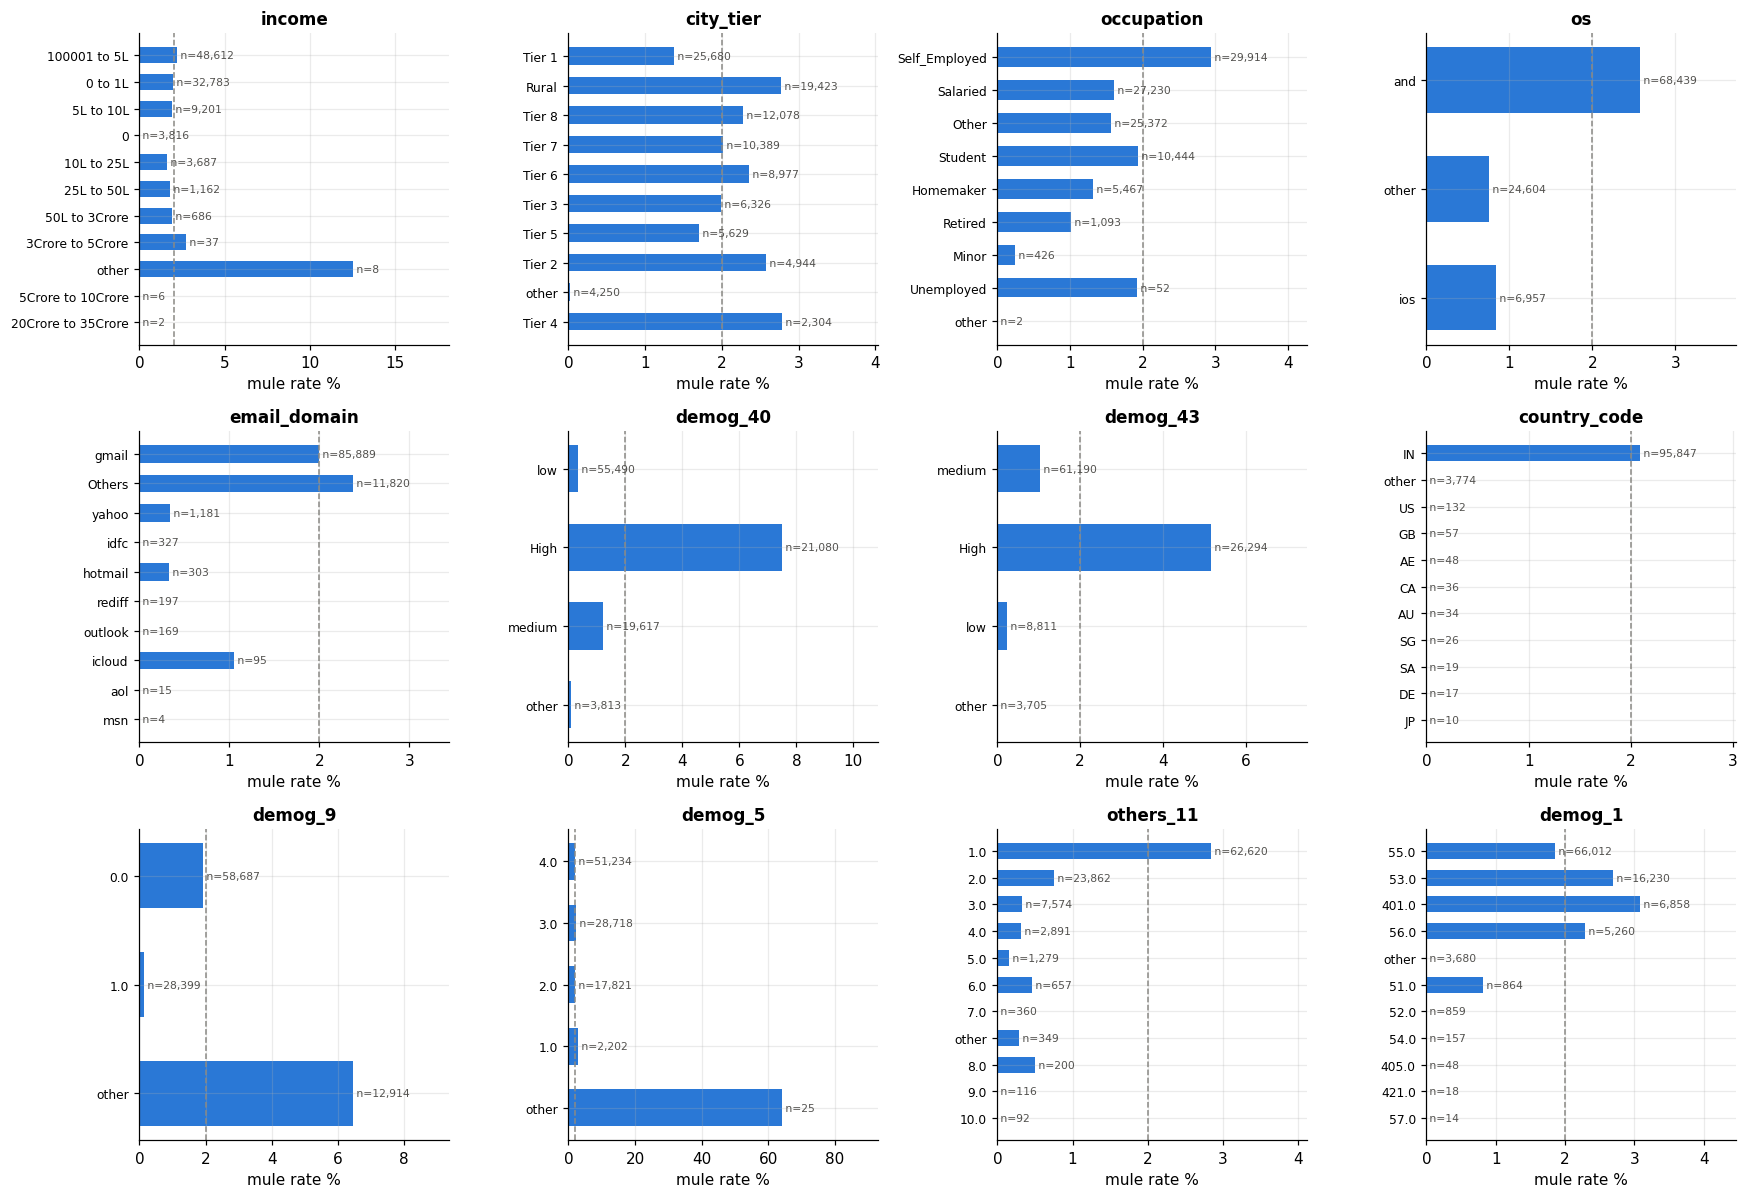

In [8]:
cats = ['income', 'city_tier', 'occupation', 'os', 'email_domain', 'demog_40', 'demog_43', 'country_code', 'demog_9', 'demog_5', 'others_11', 'demog_1']
fig, axes = plt.subplots(3, 4, figsize=(16, 11))
for ax, c in zip(axes.flat, cats):
    s = train[c].astype(str)
    top = s.value_counts().index[:10]
    g = y.groupby(s.where(s.isin(top), 'other')).agg(['mean', 'size']).sort_values('size')
    ax.barh(g.index, g['mean'] * 100, color=BLUE, height=.6)
    for i, (r, n) in enumerate(zip(g['mean'] * 100, g['size'])):
        ax.text(r, i, f' n={n:,}', va='center', fontsize=7, color='#52514e')
    ax.axvline(100 * p, color=GRAY, ls='--', lw=1)
    ax.set_title(c); ax.set_xlabel('mule rate %'); ax.tick_params(axis='y', labelsize=8)
    ax.set_xlim(0, max(g['mean'].max() * 100 * 1.45, 3))
plt.tight_layout(); plt.show()

## 6. Account-opening date
Volume and mule rate are drawn on **separate** panels (no dual axis).

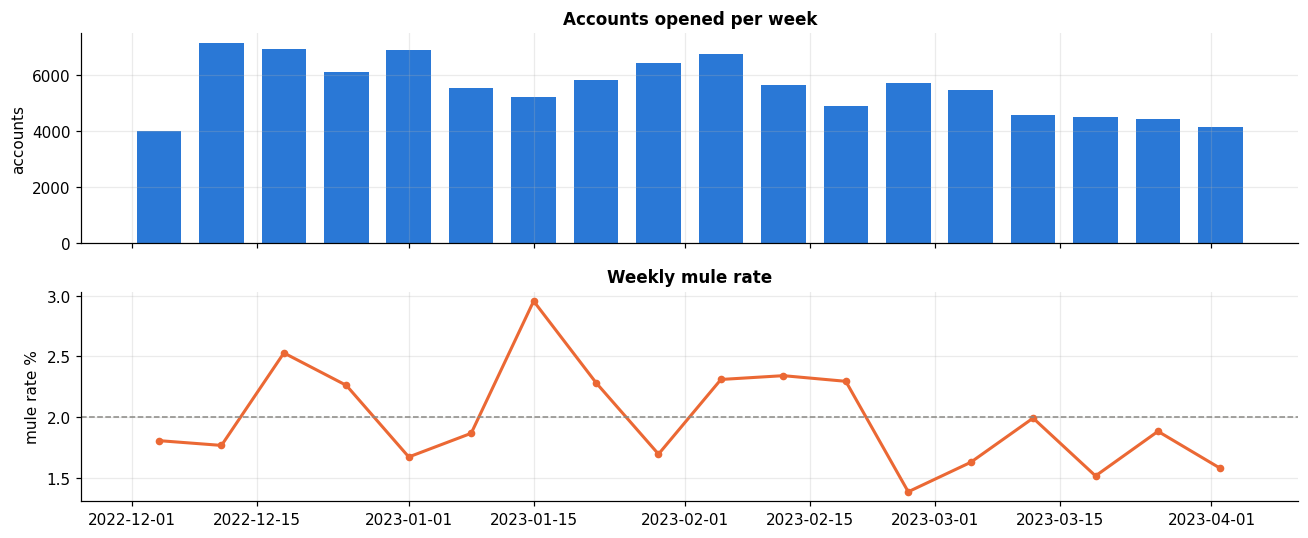

account_opening_date    Friday    Monday  Saturday   Sunday  Thursday   Tuesday  Wednesday
mean                      1.99      2.02      2.03     2.29      2.09      2.02       1.73
size                  16892.00  15492.00  12279.00  7467.00  15765.00  15669.00   16436.00
opening-date range  train: 2022-12-01 → 2023-03-31 | validation: 2022-12-01 → 2023-03-31


In [9]:
wk = train.groupby(pd.Grouper(key='account_opening_date', freq='W'))[TARGET].agg(['size', 'mean'])
fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
a1.bar(wk.index, wk['size'], width=5, color=BLUE); a1.set(title='Accounts opened per week', ylabel='accounts')
a2.plot(wk.index, wk['mean'] * 100, color=ORANGE, lw=2, marker='o', ms=4); a2.axhline(100 * p, color=GRAY, ls='--', lw=1)
a2.set(title='Weekly mule rate', ylabel='mule rate %')
plt.tight_layout(); plt.show()

dow = y.groupby(train.account_opening_date.dt.day_name()).agg(['mean', 'size'])
print((dow.assign(mean=lambda d: (d['mean'] * 100).round(2))).T)
print('opening-date range  train:', train.account_opening_date.min().date(), '→', train.account_opening_date.max().date(),
      '| validation:', valid.account_opening_date.min().date(), '→', valid.account_opening_date.max().date())

## 7. Univariate signal of every numeric feature
ROC-AUC of each raw feature on its own (NaN → −999, so missingness counts as a value). AUC is shown as
`max(AUC, 1−AUC)` so direction does not matter.

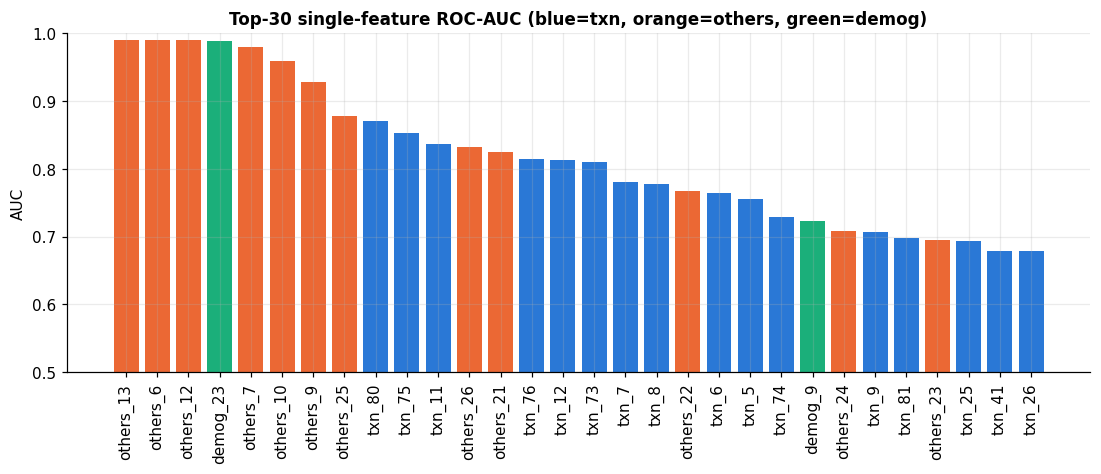

,auc,direction
others_13,0.990708,lower → mule
others_6,0.990605,lower → mule
others_12,0.990466,lower → mule
demog_23,0.989162,lower → mule
others_7,0.979691,lower → mule
others_10,0.958331,lower → mule
others_9,0.928743,lower → mule
others_25,0.877595,higher → mule
txn_80,0.870656,higher → mule
txn_75,0.853477,higher → mule


In [10]:
num = train[FEATURES].select_dtypes('number')
auc = {}
for c in num.columns:
    x = num[c].fillna(-999)
    if x.nunique() > 1:
        a = roc_auc_score(y, x); auc[c] = (max(a, 1 - a), 'higher → mule' if a > .5 else 'lower → mule')
auc = pd.DataFrame(auc, index=['auc', 'direction']).T.sort_values('auc', ascending=False)
top = auc.head(30)
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(top.index, top.auc.astype(float), color=[{'txn': BLUE, 'others': ORANGE, 'demog': AQUA}.get(group[c], GRAY) for c in top.index])
ax.set_ylim(.5, 1); ax.tick_params(axis='x', rotation=90)
ax.set(title='Top-30 single-feature ROC-AUC (blue=txn, orange=others, green=demog)', ylabel='AUC')
plt.show()
auc.head(12)

## 8. The "day-counter" columns — the strongest (and most suspicious) signal
`others_6/7/9/10/12/13/15/16` and `demog_23` have single-feature AUC ≈ 0.99. Their values look like **day counts**.
Hypothesis: they count days since the account / relationship opened, measured up to a data-snapshot date.
If so, `others_13 − (days from opening to 31-Mar-2023)` should be a constant for most accounts.

In [11]:
age_at_last_open = (train.account_opening_date.max() - train.account_opening_date).dt.days
offset = (train.others_13 - age_at_last_open).mode()[0]
snapshot = train.account_opening_date.max() + pd.Timedelta(days=int(offset))
print(f'most common offset = {offset} days  ->  implied snapshot date = {snapshot.date()}')
expected_age = (snapshot - train.account_opening_date).dt.days    # days the account *should* have existed at snapshot

day_cols = ['others_13', 'others_12', 'others_6', 'demog_23', 'others_7', 'others_10', 'others_9', 'others_15', 'others_16']
share = pd.DataFrame({c: {'legit: counter == expected age': (train[c] == expected_age)[y == 0].mean(),
                          'legit: counter < expected age': (train[c] < expected_age)[y == 0].mean(),
                          'mule: counter < expected age': (train[c] < expected_age)[y == 1].mean()} for c in day_cols}).T
(share * 100).round(1)

most common offset = 127 days  ->  implied snapshot date = 2023-08-05


,legit: counter == expected age,legit: counter < expected age,mule: counter < expected age
others_13,96.6,3.2,100.0
others_12,96.1,2.8,99.9
others_6,95.8,2.7,99.9
demog_23,93.9,2.5,99.8
others_7,91.5,8.4,100.0
others_10,83.2,16.8,100.0
others_9,70.2,2.0,92.2
others_15,55.0,2.6,86.2
others_16,55.1,2.7,86.2


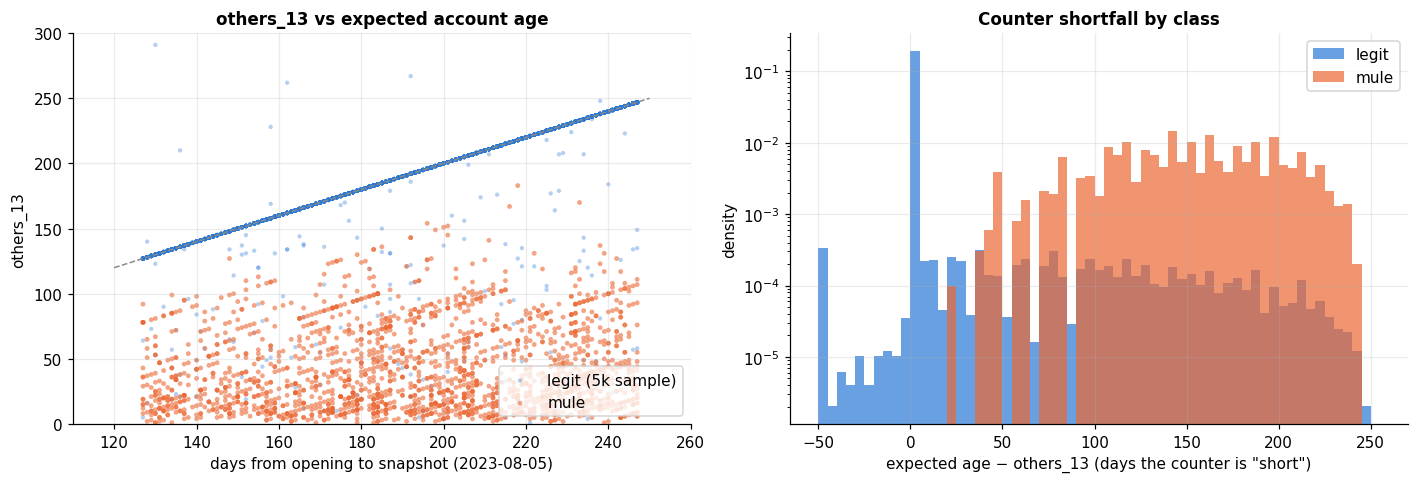

AUC of the shortfall alone: 0.9918


In [12]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
legit = train[y == 0].sample(5000, random_state=0)
a1.scatter(expected_age[legit.index], legit.others_13, s=8, color=BLUE, alpha=.35, label='legit (5k sample)', edgecolors='none')
a1.scatter(expected_age[y == 1], train.others_13[y == 1], s=10, color=ORANGE, alpha=.6, label='mule', edgecolors='none')
a1.plot([120, 250], [120, 250], color=GRAY, ls='--', lw=1)
a1.set(xlim=(110, 260), ylim=(0, 300), xlabel=f'days from opening to snapshot ({snapshot.date()})', ylabel='others_13',
       title='others_13 vs expected account age')
a1.legend(loc='lower right')
gap = expected_age - train.others_13
bins = np.arange(-50, 260, 5)
a2.hist(gap[y == 0].clip(-50, 255), bins=bins, color=BLUE, alpha=.7, density=True, label='legit')
a2.hist(gap[y == 1].clip(-50, 255), bins=bins, color=ORANGE, alpha=.7, density=True, label='mule')
a2.set(xlabel='expected age − others_13 (days the counter is "short")', ylabel='density', title='Counter shortfall by class', yscale='log')
a2.legend(); plt.tight_layout(); plt.show()
print(f'AUC of the shortfall alone: {roc_auc_score(y, gap):.4f}')

counter stopped before the snapshot: mules 100.0% | legit 3.2%
weekday on which the counter stopped (closed accounts only):
Target     legit  mule
row_0                 
Friday        88     0
Monday        84     0
Saturday    1841  1291
Sunday       101     0
Thursday      84     0
Tuesday       91     0
Wednesday    821   709


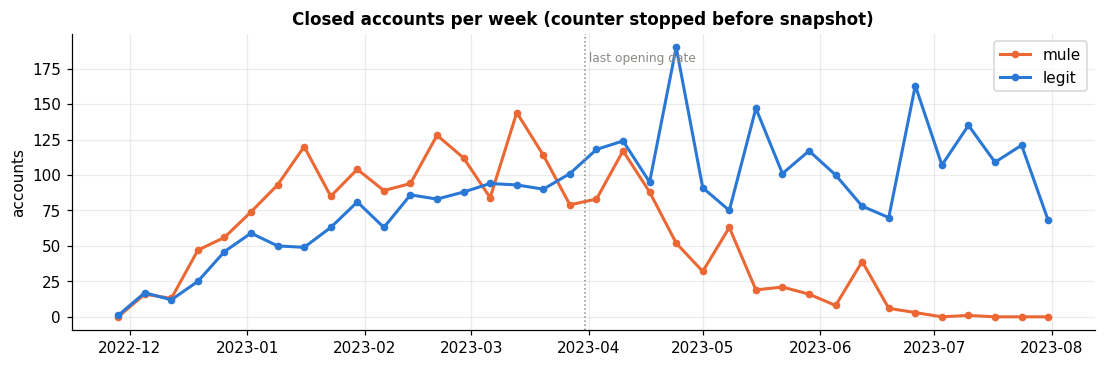

In [13]:
stop = train.account_opening_date + pd.to_timedelta(train.others_13, unit='D')   # date the counter stopped
closed = stop < snapshot
print(f'counter stopped before the snapshot: mules {closed[y == 1].mean():.1%} | legit {closed[y == 0].mean():.1%}')
print('weekday on which the counter stopped (closed accounts only):')
print(pd.crosstab(stop[closed].dt.day_name(), y[closed].map({0: 'legit', 1: 'mule'})))
wk_stop = pd.crosstab(stop[closed].dt.to_period('W').dt.start_time, y[closed].map({0: 'legit', 1: 'mule'}))
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(wk_stop.index, wk_stop['mule'], color=ORANGE, lw=2, marker='o', ms=4, label='mule')
ax.plot(wk_stop.index, wk_stop['legit'], color=BLUE, lw=2, marker='o', ms=4, label='legit')
ax.axvline(train.account_opening_date.max(), color=GRAY, ls=':', lw=1); ax.text(train.account_opening_date.max(), ax.get_ylim()[1] * .9, ' last opening date', fontsize=8, color=GRAY)
ax.set(title='Closed accounts per week (counter stopped before snapshot)', ylabel='accounts'); ax.legend(); plt.show()

**Reading.** For ~97% of legit accounts `others_13` equals the account's age at the snapshot exactly (the diagonal).
For **every** mule the counter is *short* — it stopped ~20–240 days after opening. The natural explanation is that
these counters run until the account is **closed / frozen**, and mule accounts get frozen once they are caught.
This is **target leakage**: in a real-time monitoring system the counter is only "short" *after* the bank has
already acted, so a model that relies on it detects mules the bank has already caught. **Decision: the counters are
excluded from the model** (the same columns exist in the validation file, so they would inflate the score of this
exercise, but a model built on them would be useless in production).

## 9. Transaction behaviour of mules vs legit accounts
Top transaction features (by AUC), `log1p` scale, density-normalised so the two classes are comparable.

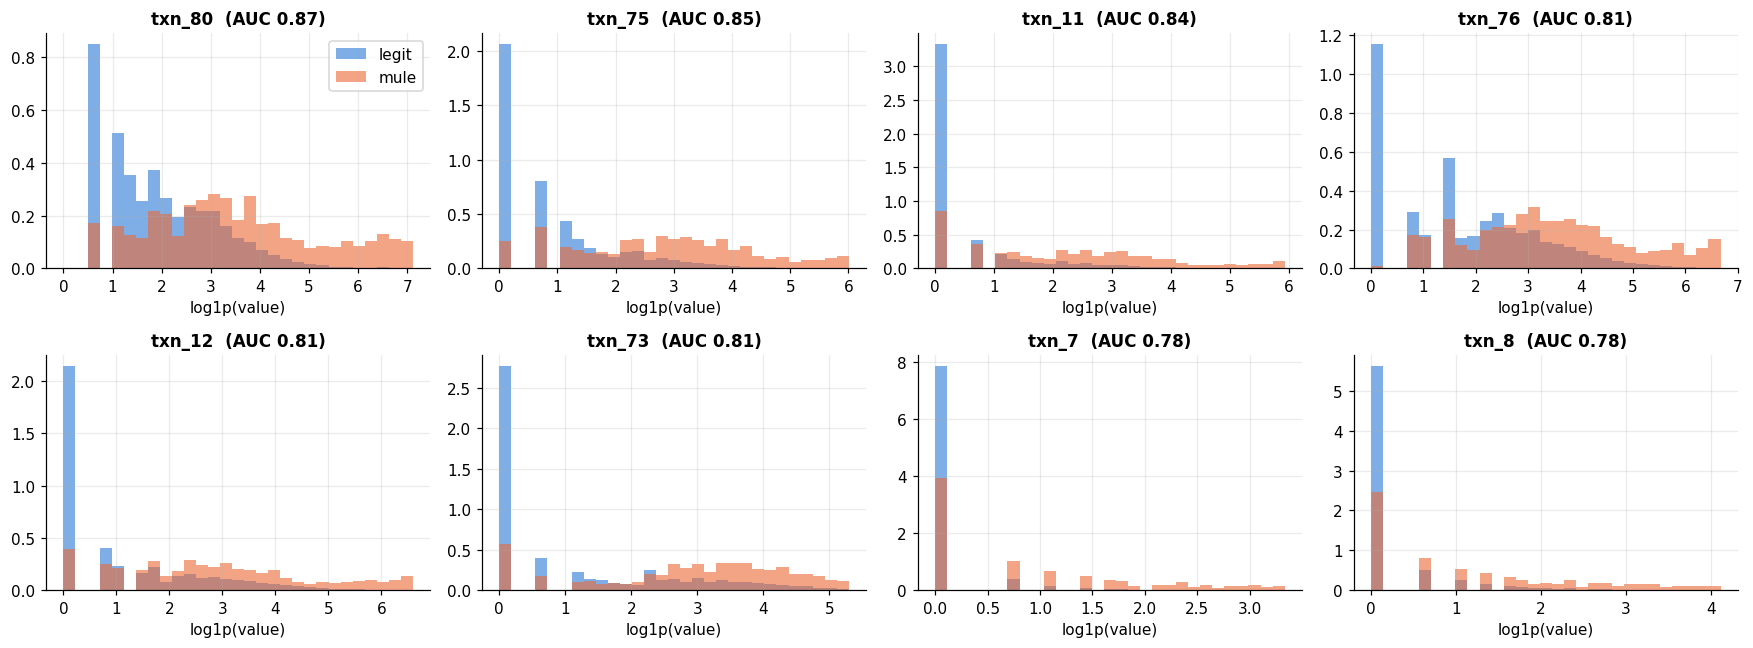

txn features where mules have >= 5x the legit mean:


,legit,mule,mule / legit
txn_5,0.60,85.19,140.96
txn_11,3.63,359.56,99.08
txn_75,5.53,381.13,68.89
txn_17,0.01,1.01,67.41
txn_3,0.11,4.40,38.36
txn_6,3.05,116.35,38.09
txn_1,0.07,2.34,32.81
txn_7,0.45,14.41,32.20
txn_12,13.09,405.11,30.94
txn_76,18.88,433.40,22.96


In [14]:
txn_top = [c for c in auc.index if c.startswith('txn')][:8]
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, c in zip(axes.flat, txn_top):
    x = np.log1p(train[c].clip(lower=0))
    bins = np.linspace(0, x.quantile(.995), 30)
    ax.hist(x[y == 0].dropna(), bins=bins, density=True, color=BLUE, alpha=.6, label='legit')
    ax.hist(x[y == 1].dropna(), bins=bins, density=True, color=ORANGE, alpha=.6, label='mule')
    ax.set_title(f'{c}  (AUC {float(auc.loc[c, "auc"]):.2f})'); ax.set_xlabel('log1p(value)')
axes[0, 0].legend(); plt.tight_layout(); plt.show()

act = train[[c for c in FEATURES if c.startswith('txn_') and int(c.split('_')[1]) <= 76]]
summary = pd.DataFrame({'legit': act[y == 0].describe().T['mean'], 'mule': act[y == 1].describe().T['mean']})
summary['mule / legit'] = summary.mule / summary.legit
print('txn features where mules have >= 5x the legit mean:')
summary[summary['mule / legit'] >= 5].sort_values('mule / legit', ascending=False).round(2).head(15)

## 10. Redundancy among transaction features (Spearman correlation)

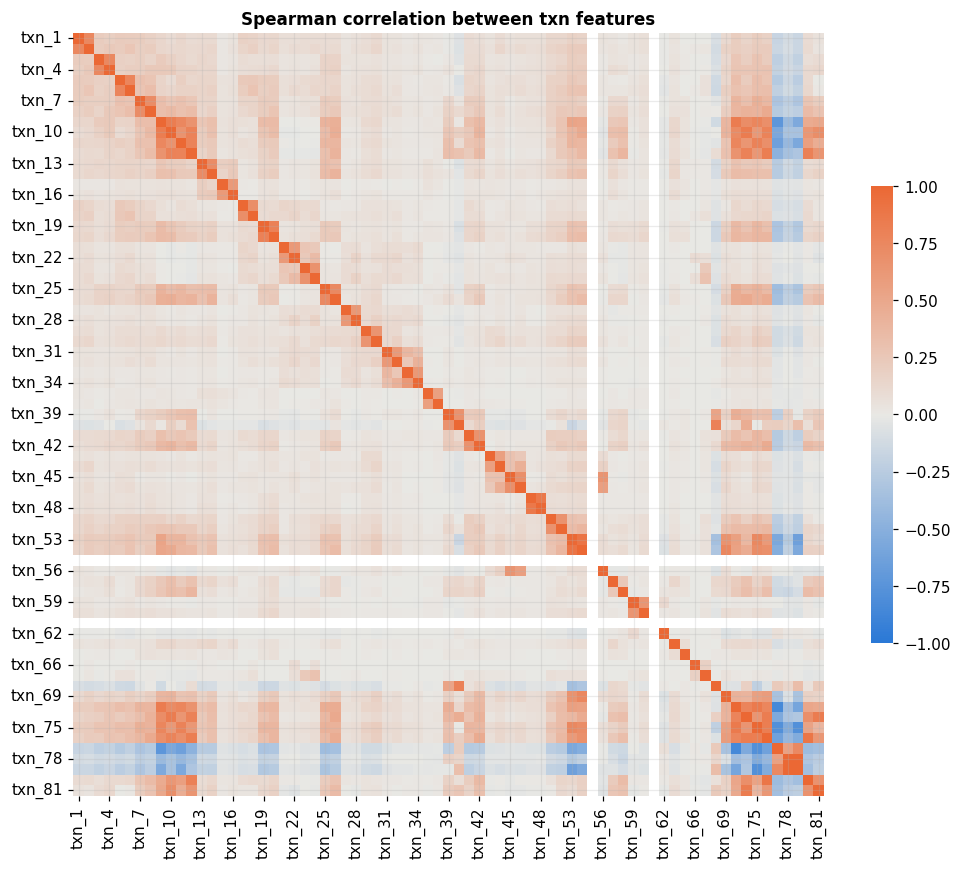

28 of 36 consecutive (odd, even) txn pairs satisfy txn_odd <= txn_even in 100% of rows
pairs that are NOT nested: {'txn_57≤txn_58': 0.855, 'txn_59≤txn_60': 0.988, 'txn_61≤txn_62': 1.0, 'txn_63≤txn_64': 0.984, 'txn_67≤txn_68': 0.999, 'txn_69≤txn_70': 0.238, 'txn_77≤txn_78': 0.454, 'txn_79≤txn_80': 0.4}
1 txn pairs with |rho| > 0.95, e.g.:


txn_78  txn_79    1.0
dtype: float64

In [15]:
txn_cols = [c for c in FEATURES if c.startswith('txn_') and train[c].nunique() > 1]
corr = train[txn_cols].sample(30000, random_state=0).corr(method='spearman')
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap=DIVERGING, vmin=-1, vmax=1, center=0, ax=ax, xticklabels=3, yticklabels=3, cbar_kws={'shrink': .6})
ax.set_title('Spearman correlation between txn features'); plt.show()
pairs = [(a, a + 1) for a in range(1, 80, 2) if train[f'txn_{a}'].nunique() > 1]
nested = pd.Series({f'txn_{a}≤txn_{b}': (train[f'txn_{b}'] >= train[f'txn_{a}'])[train[f'txn_{a}'].notna()].mean() for a, b in pairs})
print(f'{(nested == 1).sum()} of {len(nested)} consecutive (odd, even) txn pairs satisfy txn_odd <= txn_even in 100% of rows')
print('pairs that are NOT nested:', nested[nested < 1].round(3).to_dict())
upper = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack()
print(f'{(upper.abs() > .95).sum()} txn pairs with |rho| > 0.95, e.g.:')
upper[upper.abs() > .95].sort_values(ascending=False).head(10)

## 11. Train vs validation — same population?
**Adversarial validation**: train a classifier to tell development rows from validation rows. AUC ≈ 0.5 means the
two files come from the same distribution, so cross-validation on the development data is a trustworthy proxy for
the validation score.

In [16]:
import xgboost as xgb
from sklearn.model_selection import cross_val_predict, StratifiedKFold

both = pd.concat([train[FEATURES].assign(is_valid=0), valid[FEATURES].assign(is_valid=1)], ignore_index=True)
Xa = both.drop(columns='is_valid')
Xa['account_opening_date'] = Xa.account_opening_date.astype('int64') // 86_400_000_000
for c in Xa.select_dtypes(exclude='number').columns:
    Xa[c] = Xa[c].astype('category')
adv = xgb.XGBClassifier(n_estimators=200, max_depth=6, learning_rate=.1, device='cuda', tree_method='hist', enable_categorical=True)
pa = cross_val_predict(adv, Xa, both.is_valid, cv=StratifiedKFold(3, shuffle=True, random_state=0), method='predict_proba')[:, 1]
print(f'adversarial AUC = {roc_auc_score(both.is_valid, pa):.4f}')

cmp = pd.DataFrame({'train_missing_%': train[FEATURES].isna().mean() * 100, 'valid_missing_%': valid[FEATURES].isna().mean() * 100})
print('largest missing-rate differences:'); cmp.assign(diff=lambda d: (d.iloc[:, 0] - d.iloc[:, 1]).abs()).nlargest(5, 'diff').round(2)

/home/sarthak/miniconda3/lib/python3.13/site-packages/xgboost/core.py:751: UserWarning: [10:31:53] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


adversarial AUC = 0.4992
largest missing-rate differences:


,train_missing_%,valid_missing_%,diff
txn_80,57.48,57.73,0.25
txn_77,45.42,45.64,0.22
txn_81,51.46,51.62,0.15
txn_78,56.73,56.88,0.15
others_43,95.42,95.57,0.15


## 12. Summary & what it means for modelling
| # | Finding | Modelling decision |
|---|---|---|
| 1 | **2.00% mules (1:49).** No-skill reference: log-loss 0.098, Brier 0.0196. | Weighted log-loss (`scale_pos_weight ≈ 49`). Because scoring is about probability accuracy, the weighted model **must be re-calibrated**. Track PR-AUC (ranking under imbalance) **and** log-loss / Brier (calibration). |
| 2 | **Missing values come in blocks and are informative.** Txn block (76 cols, 25.8% NA) → 0.5% mules (inactive accounts); `country_code/demog_1/demog_2` block → 0 mules; `demog_9` NA → 6.5%; `demog_24/26` NA → 16%; `demog_5` NA → 64% (n=25). | Keep NaN for tree models (they learn a direction for missing), add missing-block indicators/counts, *test* imputation vs native NaN. Drop >95%-missing `others_42–45` only if they don't help. |
| 3 | **Data-quality issues:** the development file is **sorted by target** (all mules are keys 98,001–100,000); 12 constant columns; `9999` sentinel in `others_27/28` (98–99% of rows); mixed-type codes (`demog_2` has `'ZZ'`, `demog_4` has `'N'`, `income` has `'0'`); 3.7k exact-duplicate rows (all legit, inactive). | Never use `Primary key` as a feature and always shuffle before splitting (stratified, shuffled K-fold). Drop constants, turn sentinel into NaN, encode categoricals (ordinal where ordered: income, city tier, low/medium/High). Keep duplicates: they are real population and matter for calibration. |
| 4 | **Mule profile:** self-employed, Android, single-product customers (`others_11 = 1`), `demog_40/43 = High` (7.5% / 5.2%), Indian only (0 mules among 3.7k non-IN), `demog_9 = 0`, and very high transaction volumes (`txn_5`, `txn_11`, `txn_75` have 70–140× the legit mean). | These go straight into the model; add aggregate activity features. |
| 5 | **Leak-like day counters.** `others_6/7/10/12/13`, `demog_23` count days since opening up to a snapshot (2023-08-05) *or until the account was closed*. 100% of mules are closed (batch freezes on Sat/Wed) vs 3.2% of legit. Counter shortfall alone: AUC 0.992. | **Exclude all 9 counters from the model.** They record the bank's reaction (the freeze), not mule behaviour, and on the open accounts a live monitor scores they equal the account age for everyone. Notebook 02 shows the baseline is "too good" because of them; notebook 04 quantifies what they would add and audits all other features for the same problem. |
| 6 | **Txn features are nested (short, long) window pairs** (`txn_odd ≤ txn_even` in 100% of rows for 28 pairs); `txn_78` and `txn_79` are rank-identical. | Ratio features `txn_odd / txn_even` (how much activity is recent = burst behaviour). |
| 7 | **Train and validation are the same population** (adversarial AUC 0.499, missing rates within 0.25 pp; same opening dates). | Stratified K-fold CV on development data is a reliable proxy for the validation score. |
| 8 | Opening month / weekday barely matter (1.7–2.3%). | Keep only as weak features. |